# LM22 Lab — Resampling Methods

Companion notebook to **From Calculus to Kelly, LM22**. It rebuilds the module's exhibits and computational examples from TR23's closes and the repaired sector closes, with the seeds the module prints, solves the computational practice problems, and ends with an extension exercise. A full run takes a few minutes: it solves the exact Kelly condition in 20,000 resamples of 5,849 days.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23's returns, $T$, $A$, the moments and the two limit regimes; U28 after the repair cell, and the pair |
| 2 | Example 1 by enumeration and with $B=1{,}000$ |
| 3 | iid and stationary resamples of TR23 (experiments 2 and 3): Exhibit 1, Example 2, Example 3, Exhibit 2, Exhibit 3, and SciPy's `bootstrap` on stream 2 re-created |
| 4 | What resampling days cannot see: Example 4, Exhibit 4 |
| 5 | The three block functions and the arch check; Example 5, Exhibit 5, Exhibit 6 |
| 6 | `optimal_block_length`, the book's rule (Example 6) and Exhibit 7 |
| 7 | Intervals the earlier modules left open: Example 7, Example 8, Example 9, Exhibit 8 |
| 8 | Bootstrap tests: Example 10 and the knowledge check of Section 8 |
| 9 | Problems 6, 10 and 11, and an extension exercise (the pair's correlation in the two limit regimes) |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv` (`date`, `price`: the closes of the TAIEX total-return index that FinMind's `TaiwanStockTotalReturnIndex` serves, 2003-01-02 → 2026-10-08), `sectors_close_raw.csv` (the closes FinMind's `TaiwanStockPrice` serves for TAIEX and the 30 TWSE sector indices, one column per series) and `sectors_close_repairs.csv` (each of the 561 closes that FinMind copied from another date or series, with its official 13:30:00 value from `TaiwanStockEvery5SecondsIndex`). The notebook reads nothing outside `data/`.

**Conventions (as in the module).** TR23: $T=5{,}849$ daily simple returns $R_t=P_t/P_{t-1}-1$ from 2003-01-03, log returns $r_t=\ln(1+R_t)$, $A=T/\text{years}$ with years = calendar days ÷ 365.25; the 7% regime is the returns dated before 2015-06-01. U28: the 28 leaf TWSE sector price indices (no dividends), $T=4{,}382$ returns from 2008-12-02. Moments divide by $T$; $s_{\mathrm u}$ (divisor $T-1$) enters only the t-stat. A bootstrap standard error divides by $B$; every quantile is the order statistic $\lceil uB\rceil$ (`method="inverted_cdf"`); Monte Carlo errors are LM18's batch standard errors (20 batches of consecutive resamples, divisor 20). Every interval and test is in-sample; resampled paths are a model.

**The seed rule.** Each experiment creates its generator once, at its start, as `np.random.default_rng([e, 20261011])` with `e` the module's experiment number, and never reseeds it. Resamples come in chunks of 500 rows; experiments 8 to 15 draw one resample at a time, which is the same stream for iid days. Printed numbers rest on the NumPy version that `uv.lock` pins. `show(...)` prints each value next to the module's and asserts that they agree.

In [1]:
from datetime import date
from fractions import Fraction
from itertools import product
from pathlib import Path
from types import SimpleNamespace as NS
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy import stats
from arch.bootstrap import (CircularBlockBootstrap, MovingBlockBootstrap, StationaryBootstrap,
                            optimal_block_length)

DATA = Path("data")
SEED, CH, B, EPS = 20261011, 500, 10_000, 1e-12
FIRST_CLOSE, LAST_CLOSE = "2008-12-01", "2026-10-08"            # U28's closes
AGGREGATES = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def rng(e):
    # the generator of experiment e: its number first, then the root seed
    return np.random.default_rng([e, SEED])


def pct(v):
    # the 95% percentile ends: order statistics ceil(0.025 B) and ceil(0.975 B)
    q = np.quantile(v, [0.025, 0.975], method="inverted_cdf")
    return float(q[0]), float(q[1])


def bse(v, fn):
    # LM18's batch standard error: fn on 20 batches of consecutive resamples, their SD (divisor 20) over sqrt(20)
    vals = np.array([fn(c) for c in np.split(v, 20)])
    return float(vals.std() / math.sqrt(20))


def summ(v, est):
    # (22.1), (22.2) and the batch standard errors of the SE and of the two ends
    lo, hi = pct(v)
    return NS(est=est, se=float(v.std()), lo=lo, hi=hi, blo=2 * est - hi, bhi=2 * est - lo, mean=float(v.mean()),
              se_b=bse(v, np.std), lo_b=bse(v, lambda c: pct(c)[0]), hi_b=bse(v, lambda c: pct(c)[1]))


FULL_DATA = True                                  # set by the repair cell of Part 1


def show(label, value, fmt, printed, u28=False):
    # print a value next to the module's; assert equality, except for U28 numbers when closes had to be dropped
    got = format(value, fmt)
    if got.startswith("-") and float(got.replace(",", "")) == 0:
        got = got[1:]
    ok = got == printed
    note = "" if ok else ("   (differs: closes were dropped)" if u28 and not FULL_DATA else "   MISMATCH")
    print(f"{label}: {got}   [book: {printed}]{note}")
    if not u28 or FULL_DATA:
        assert ok, (label, got, printed)


def pw(x):
    # Politis and White's stationary and circular estimates; arch 8.0.0 names the columns 'stationary', 'circular'
    ob = optimal_block_length(x)
    assert list(ob.columns) == ["stationary", "circular"]
    a = ob.to_numpy()[0]
    return float(a[0]), float(a[1])

## Part 1 — Data

TR23 comes from the closes with Polars expressions. U28 needs LM16's repair cell first: FinMind's `TaiwanStockPrice` serves some sector closes copied from another date or another series (PITFALLS §3 of the repository), and the book replaces each of these 561 closes with the official 13:30:00 value. On FinMind's free plan the 13:30:00 values are not available (`TaiwanStockEvery5SecondsIndex` is a paid dataset), so `close_1330` is empty and the cell **drops** those closes instead: the U28 sample then keeps 4,307 of its 4,382 returns, and every U28 number below differs slightly from the module's (`show` says so instead of stopping). Nothing is ever estimated. TR23 needs no repair.

In [2]:
raw = pl.read_csv(DATA / "taiex_tr.csv", try_parse_dates=True).sort("date")
tr = (raw.with_columns((pl.col("price") / pl.col("price").shift(1) - 1).alias("R"))
         .with_columns(pl.col("R").log1p().alias("r"))
         .slice(1))
R, r = tr["R"].to_numpy(), tr["r"].to_numpy()
T = R.size
dates = [d.isoformat() for d in tr["date"].to_list()]
days = (raw["date"][-1] - raw["date"][0]).days
A = T / (days / 365.25)
SQA = math.sqrt(A)
Rbar, s = R.mean(), R.std()                        # divisor T
rbar, s_r = r.mean(), r.std()
skew = ((R - Rbar) ** 3).mean() / s**3
kurt = ((R - Rbar) ** 4).mean() / s**4
pre = tr.select(pl.col("date") < pl.lit(date(2015, 6, 1))).to_series().to_numpy()
print(f"TR23: {raw.height} closes {raw['date'][0]} .. {raw['date'][-1]}; T = {T} returns from {dates[0]}")
show("T", T, ",", "5,849")
show("A", A, ".2f", "246.12")
show("mean R, %", 100 * Rbar, ".6f", "0.062505")
show("s, %", 100 * s, ".4f", "1.2084")
show("Kurt (LM14's)", kurt, ".2f", "8.27")
show("7% regime returns (to 2015-05-29)", int(pre.sum()), ",", "3,077")
show("10% regime returns", int((~pre).sum()), ",", "2,772")
SR_d, KEL, VOL = Rbar / s, Rbar / s**2, s * SQA
show("Sharpe ratio a day (LM19's)", SR_d, ".4f", "0.0517")
show("   annualized", SR_d * SQA, ".2f", "0.81")
show("Kelly fraction f_hat = Rbar / s^2 (LM20's)", KEL, ".2f", "4.28")
show("volatility, % a year (LM19's)", 100 * VOL, ".2f", "18.96")

TR23: 5850 closes 2003-01-02 .. 2026-10-08; T = 5849 returns from 2003-01-03
T: 5,849   [book: 5,849]
A: 246.12   [book: 246.12]
mean R, %: 0.062505   [book: 0.062505]
s, %: 1.2084   [book: 1.2084]
Kurt (LM14's): 8.27   [book: 8.27]
7% regime returns (to 2015-05-29): 3,077   [book: 3,077]
10% regime returns: 2,772   [book: 2,772]
Sharpe ratio a day (LM19's): 0.0517   [book: 0.0517]
   annualized: 0.81   [book: 0.81]
Kelly fraction f_hat = Rbar / s^2 (LM20's): 4.28   [book: 4.28]
volatility, % a year (LM19's): 18.96   [book: 18.96]


In [3]:
sraw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
series = [c for c in sraw.columns if c != "date"]
fixed = sraw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
n_listed, n_replaced = rep.height, int(rep["close_1330"].is_not_null().sum())
FULL_DATA = n_replaced == n_listed
print("Rule: every close listed in sectors_close_repairs.csv is replaced by its 13:30:00 value (close_1330);")
print("      a listed close without that value is dropped (set to missing), never estimated.")
print(f"listed closes {n_listed}: replaced {n_replaced}, dropped {n_listed - n_replaced}")
U28 = [c for c in series if c not in ("TAIEX", *AGGREGATES)]
closes = fixed.filter(pl.col("date").is_between(pl.lit(FIRST_CLOSE), pl.lit(LAST_CLOSE))).sort("date")
uret = (closes.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in series]).slice(1)
              .filter(pl.all_horizontal([pl.col(c).is_not_null() for c in ["TAIEX", *U28]])))
X = uret.select(U28).to_numpy()                     # T_U x 28, the sectors in alphabetical order
udates = uret["date"].to_list()
TU = X.shape[0]
PAIR = X[:, [U28.index("Semiconductor"), U28.index("FinancialInsurance")]]
uyear = np.array([d[:4] for d in udates])
show("U28 returns", TU, ",", "4,382", u28=True)
print(f"U28: {udates[0]} .. {udates[-1]}; the pair: Semiconductor, FinancialInsurance (price indices, no dividends)")

Rule: every close listed in sectors_close_repairs.csv is replaced by its 13:30:00 value (close_1330);
      a listed close without that value is dropped (set to missing), never estimated.
listed closes 561: replaced 561, dropped 0
U28 returns: 4,382   [book: 4,382]
U28: 2008-12-02 .. 2026-10-08; the pair: Semiconductor, FinancialInsurance (price indices, no dividends)


## Part 2 — The ideal bootstrap of five returns

**Example 1.** All $5^5=3{,}125$ ordered resamples of LM18's five returns are equally likely, so the ideal bootstrap is an average over them. The median of five draws is $\hat F^{-1}(\tfrac12)$, the third smallest. Then experiment 1 estimates both standard errors from $B=1{,}000$ resamples.

In [4]:
five = np.array([0.012, -0.008, 0.003, -0.025, 0.006])
allres = five[np.array(list(product(range(5), repeat=5)))]
mean_all = allres.mean(axis=1)
med_all = np.quantile(allres, 0.5, axis=1, method="inverted_cdf")
show("mean, %", 100 * five.mean(), ".2f", "-0.24")
show("s, %", 100 * five.std(), ".4f", "1.3032")
show("ideal SE of the mean, %", 100 * mean_all.std(), ".3f", "0.583")
print(f"   s / sqrt(5) = {100 * five.std() / math.sqrt(5):.6f}% (exactly the same, (18.8))")
for x in np.sort(five):
    print(f"   Pr(median = {100 * x:+.1f}%) = {Fraction(int((med_all == x).sum()), 3125)}")
show("ideal SE of the median, %", 100 * med_all.std(), ".3f", "0.859")
b1 = five[rng(1).integers(0, 5, size=(1000, 5))]  # experiment 1
m1, md1 = b1.mean(axis=1), np.quantile(b1, 0.5, axis=1, method="inverted_cdf")
show("B = 1,000: SE of the mean, %", 100 * m1.std(), ".2f", "0.59")
show("   its batch SE, %", 100 * bse(m1, np.std), ".2f", "0.01")
show("B = 1,000: SE of the median, %", 100 * md1.std(), ".2f", "0.87")
show("   its batch SE, %", 100 * bse(md1, np.std), ".2f", "0.02")

mean, %: -0.24   [book: -0.24]
s, %: 1.3032   [book: 1.3032]
ideal SE of the mean, %: 0.583   [book: 0.583]
   s / sqrt(5) = 0.582821% (exactly the same, (18.8))
   Pr(median = -2.5%) = 181/3125
   Pr(median = -0.8%) = 811/3125
   Pr(median = +0.3%) = 1141/3125
   Pr(median = +0.6%) = 811/3125
   Pr(median = +1.2%) = 181/3125
ideal SE of the median, %: 0.859   [book: 0.859]
B = 1,000: SE of the mean, %: 0.59   [book: 0.59]
   its batch SE, %: 0.01   [book: 0.01]
B = 1,000: SE of the median, %: 0.87   [book: 0.87]
   its batch SE, %: 0.02   [book: 0.02]


## Part 3 — Intervals for the Sharpe ratio and the Kelly fraction

Experiment 2 resamples TR23's days iid, `integers(0, T, size=(500, T))` twenty times; experiment 3 uses the stationary bootstrap with mean block length 145 (Section 5's function, printed in Section 9 and checked against arch in Part 5). Each resample gets the five statistics of Exhibit 1 and the widget, and the exact optimum $\hat f^*$, the root of (4.5) by Newton's method kept inside its bracket ($1+fR_t>0$ on every day).

In [5]:
def stationary_idx(rng, T, ell):
    # Day indices of one stationary resample, drawn in arch's order (Section 9).
    start = rng.integers(T, size=T)        # a candidate start day per position
    new = rng.random(T) <= 1 / ell         # a new block starts here
    new[0] = True
    first = np.flatnonzero(new)            # positions where blocks start
    blk = np.cumsum(new) - 1               # the block of each position
    step = np.arange(T) - first[blk]       # steps since its block started
    return (start[first][blk] + step) % T  # day T is followed by day 1


def acf1(x):
    # LM19's (19.5) at lag 1 for each row: the row's own mean, divisor n in numerator and denominator
    c = x - x.mean(axis=-1, keepdims=True)
    return (c[..., 1:] * c[..., :-1]).sum(axis=-1) / (c * c).sum(axis=-1)


def vr(x, m):
    # LM19's (19.8) for each row of log returns: overlapping m-day sums centred at m rbar, over m s_r^2
    n = x.shape[-1]
    mu = x.mean(axis=-1, keepdims=True)
    c = np.concatenate([np.zeros(x.shape[:-1] + (1,)), np.cumsum(x, axis=-1)], axis=-1)
    sums = c[..., m:] - c[..., :-m]
    return ((sums - m * mu) ** 2).sum(axis=-1) / (n - m + 1) / (m * x.var(axis=-1))


def exact_kelly(Rx):
    # the root of (4.5), mean of R / (1 + f R) = 0, for each row: Newton from mean / var, kept inside the bracket
    m = Rx.mean(axis=-1)
    pos = m > 0
    a = np.where(pos, 0.0, -1 / Rx.max(axis=-1) * (1 - 1e-12))
    b = np.where(pos, -1 / Rx.min(axis=-1) * (1 - 1e-12), 0.0)
    f = m / Rx.var(axis=-1)
    f = np.where((f > a) & (f < b), f, (a + b) / 2)
    for _ in range(200):
        q = Rx / (1 + f[..., None] * Rx)
        h = q.mean(axis=-1)
        a, b = np.where(h > 0, f, a), np.where(h > 0, b, f)
        newton = f + h / (q * q).mean(axis=-1)
        new = np.where((newton > a) & (newton < b), newton, (a + b) / 2)
        step, f = new - f, new
        if np.abs(step).max() < 1e-12:
            break
    assert np.abs((Rx / (1 + f[..., None] * Rx)).mean(axis=-1)).max() < 1e-14
    return f


def tr_stats(Rx, exact=True):
    m, sd = Rx.mean(axis=-1), Rx.std(axis=-1)
    rx = np.log1p(Rx)
    out = {"SR": SQA * m / sd, "Kelly": m / sd**2, "vol": SQA * sd, "acf": acf1(np.abs(rx)), "VR20": vr(rx, 20)}
    if exact:
        out["fx"] = exact_kelly(Rx)
    return out


def chunks(g, n, scheme, ell, b=B):
    # b resamples of n day indices in chunks of 500 rows; scheme: "iid" or a function (g, n, ell) -> indices
    for _ in range(b // CH):
        yield g.integers(0, n, size=(CH, n)) if scheme == "iid" else np.stack([scheme(g, n, ell) for _ in range(CH)])


def boot(x, it, exact=True):
    acc = {}
    for idx in it:
        for k, v in tr_stats(x[idx], exact).items():
            acc.setdefault(k, []).append(v)
    return {k: np.concatenate(v) for k, v in acc.items()}


OBS = {k: float(v[0]) for k, v in tr_stats(R[None, :]).items()}
show("exact optimum f_hat* (LM17's)", OBS["fx"], ".2f", "4.14")
IID = boot(R, chunks(rng(2), T, "iid", 1))                 # experiment 2
SB = boot(R, chunks(rng(3), T, stationary_idx, 145))       # experiment 3
S = {k: (summ(IID[k], OBS[k]), summ(SB[k], OBS[k])) for k in IID}

exact optimum f_hat* (LM17's): 4.14   [book: 4.14]


In [6]:
rows = []
for k, name, sc, nd in (("SR", "Sharpe ratio, annualized", 1, 2), ("Kelly", "Kelly fraction f_hat", 1, 1),
                        ("vol", "Volatility, annualized (%)", 100, 1)):
    i, b = S[k]
    rows.append({"statistic": name, "estimate": OBS[k] * sc, "iid low": round(i.lo * sc, nd),
                 "iid high": round(i.hi * sc, nd), "blocks low": round(b.lo * sc, nd), "blocks high": round(b.hi * sc, nd),
                 "width ratio": (b.hi - b.lo) / (i.hi - i.lo),
                 "largest batch SE of the ends": sc * max(i.lo_b, i.hi_b, b.lo_b, b.hi_b)})
print(pl.DataFrame(rows))                                  # Exhibit 1
for k, sc, nd, p in (("SR", 1, 2, ("0.41", "1.21", "0.37", "1.27")), ("Kelly", 1, 1, ("2.2", "6.5", "1.8", "7.1")),
                     ("vol", 100, 1, ("18.3", "19.6", "16.5", "21.5"))):
    i, b = S[k]
    show(f"Exhibit 1 {k}: iid low", i.lo * sc, f".{nd}f", p[0])
    show(f"   {k}: iid high", i.hi * sc, f".{nd}f", p[1])
    show(f"   {k}: blocks low", b.lo * sc, f".{nd}f", p[2])
    show(f"   {k}: blocks high", b.hi * sc, f".{nd}f", p[3])
    show(f"   {k}: width ratio", (b.hi - b.lo) / (i.hi - i.lo), ".1f", {"SR": "1.1", "Kelly": "1.2", "vol": "3.9"}[k])

shape: (3, 8)
┌──────────────┬──────────┬─────────┬──────────┬────────────┬────────┬──────────────┬──────────────┐
│ statistic    ┆ estimate ┆ iid low ┆ iid high ┆ blocks low ┆ blocks ┆ width ratio  ┆ largest      │
│ ---          ┆ ---      ┆ ---     ┆ ---      ┆ ---        ┆ high   ┆ ---          ┆ batch SE of  │
│ str          ┆ f64      ┆ f64     ┆ f64      ┆ f64        ┆ ---    ┆ f64          ┆ the ends     │
│              ┆          ┆         ┆          ┆            ┆ f64    ┆              ┆ ---          │
│              ┆          ┆         ┆          ┆            ┆        ┆              ┆ f64          │
╞══════════════╪══════════╪═════════╪══════════╪════════════╪════════╪══════════════╪══════════════╡
│ Sharpe       ┆ 0.811509 ┆ 0.41    ┆ 1.21     ┆ 0.37       ┆ 1.27   ┆ 1.134835     ┆ 0.008199     │
│ ratio,       ┆          ┆         ┆          ┆            ┆        ┆              ┆              │
│ annualized   ┆          ┆         ┆          ┆            ┆        ┆       

**Example 2.** The bootstrap standard error (22.1) against LM20's delta method: with the sample's skewness and kurtosis, $\sqrt{(1-\widehat{\mathrm{SR}}\operatorname{Skew}+\widehat{\mathrm{SR}}^2(\operatorname{Kurt}-1)/4)/T}$ a day, and for normal returns $\sqrt{(1+\widehat{\mathrm{SR}}^2/2)/T}$. Then SciPy's `bootstrap` on stream 2 re-created: with `batch=500` it draws experiment 2's resamples exactly.

In [7]:
sr_i, sr_b = S["SR"]
show("Example 2 bootstrap SE, a year", sr_i.se, ".3f", "0.205")
show("   percentile interval low", sr_i.lo, ".2f", "0.41")
show("   percentile interval high", sr_i.hi, ".2f", "1.21")
show("   basic interval low", sr_i.blo, ".2f", "0.41")
show("   basic interval high", sr_i.bhi, ".2f", "1.21")
print(f"   batch SEs: SE {sr_i.se_b:.4f}, ends {sr_i.lo_b:.4f} and {sr_i.hi_b:.4f}")
se_sr = math.sqrt((1 - SR_d * skew + SR_d**2 * (kurt - 1) / 4) / T)
se_sr_n = math.sqrt((1 + SR_d**2 / 2) / T)
z = stats.norm.ppf(0.975)
show("   delta method SE (LM20's, plug-in moments)", se_sr * SQA, ".3f", "0.207")
show("   delta method SE (LM20's, normal returns)", se_sr_n * SQA, ".3f", "0.205")
show("   delta interval low", (SR_d - z * se_sr) * SQA, ".2f", "0.40")
show("   delta interval high", (SR_d + z * se_sr) * SQA, ".2f", "1.22")
show("   1 / sqrt(T)", 1 / math.sqrt(T), ".4f", "0.0131")
show("   bootstrap SE a day", sr_i.se / SQA, ".4f", "0.0131")
show("blocks: SE", sr_b.se, ".3f", "0.233")

Example 2 bootstrap SE, a year: 0.205   [book: 0.205]
   percentile interval low: 0.41   [book: 0.41]
   percentile interval high: 1.21   [book: 1.21]
   basic interval low: 0.41   [book: 0.41]
   basic interval high: 1.21   [book: 1.21]
   batch SEs: SE 0.0012, ends 0.0057 and 0.0048
   delta method SE (LM20's, plug-in moments): 0.207   [book: 0.207]
   delta method SE (LM20's, normal returns): 0.205   [book: 0.205]
   delta interval low: 0.40   [book: 0.40]
   delta interval high: 1.22   [book: 1.22]
   1 / sqrt(T): 0.0131   [book: 0.0131]
   bootstrap SE a day: 0.0131   [book: 0.0131]
blocks: SE: 0.233   [book: 0.233]


In [8]:
def sharpe(x, axis=-1):                    # annual Sharpe ratio, r_f = 0, with the sample's A
    return SQA * x.mean(axis=axis) / x.std(axis=axis)


def kelly(x, axis=-1):
    return x.mean(axis=axis) / x.var(axis=axis)


sp = {}
for meth in ("percentile", "basic", "BCa"):
    for name, fn in (("SR", sharpe), ("Kelly", kelly)):
        sp[meth, name] = stats.bootstrap((R,), fn, n_resamples=B, batch=CH, vectorized=True, method=meth,
                                         rng=rng(2))     # stream 2 re-created on purpose
assert np.array_equal(sp["percentile", "SR"].bootstrap_distribution, IID["SR"])
print("SciPy draws experiment 2's resamples exactly")
ci = {key: (float(v.confidence_interval.low), float(v.confidence_interval.high)) for key, v in sp.items()}
show("SciPy percentile low (linear interpolation)", ci["percentile", "SR"][0], ".4f", "0.4157")
show("   the book's order statistic", sr_i.lo, ".4f", "0.4147")
show("SciPy standard_error (divisor B - 1)", float(sp["percentile", "SR"].standard_error), ".5f", "0.20539")
show("   the book's (divisor B)", sr_i.se, ".5f", "0.20538")
show("SciPy BCa, Sharpe ratio: low", ci["BCa", "SR"][0], ".2f", "0.42")
show("   high", ci["BCa", "SR"][1], ".2f", "1.22")

SciPy draws experiment 2's resamples exactly
SciPy percentile low (linear interpolation): 0.4157   [book: 0.4157]
   the book's order statistic: 0.4147   [book: 0.4147]
SciPy standard_error (divisor B - 1): 0.20539   [book: 0.20539]
   the book's (divisor B): 0.20538   [book: 0.20538]
SciPy BCa, Sharpe ratio: low: 0.42   [book: 0.42]
   high: 1.22   [book: 1.22]


**Example 3, Exhibit 2 and Exhibit 3.** The Kelly fraction $\hat f$ and the exact optimum $\hat f^*$ on the same resamples, against LM20's delta method (20.9).

In [9]:
k_i, k_b = S["Kelly"]
fx_i, fx_b = S["fx"]
se_k = math.sqrt((1 - 2 * SR_d * skew + SR_d**2 * (kurt - 1)) / (s**2 * T))
show("Example 3 iid SE", k_i.se, ".2f", "1.10")
show("   percentile", k_i.lo, ".1f", "2.2"); show("   ...", k_i.hi, ".1f", "6.5")
show("   basic", k_i.blo, ".1f", "2.1"); show("   ...", k_i.bhi, ".1f", "6.4")
show("   SciPy BCa", ci["BCa", "Kelly"][0], ".1f", "2.2"); show("   ...", ci["BCa", "Kelly"][1], ".1f", "6.5")
show("   delta SE (LM20's, plug-in)", se_k, ".3f", "1.111")
show("   delta SE, normal returns", math.sqrt((1 + 2 * SR_d**2) / (s**2 * T)), ".3f", "1.085")
show("   delta SE, mean only", 1 / (s * math.sqrt(T)), ".3f", "1.082")
show("   delta interval low", KEL - z * se_k, ".2f", "2.10"); show("   ...", KEL + z * se_k, ".2f", "6.46")
show("exact optimum, iid: SE", fx_i.se, ".2f", "1.03")
show("   percentile", fx_i.lo, ".1f", "2.1"); show("   ...", fx_i.hi, ".1f", "6.1")
show("blocks: f_hat percentile", k_b.lo, ".1f", "1.8"); show("   ...", k_b.hi, ".1f", "7.1")
show("blocks: f_hat basic", k_b.blo, ".1f", "1.5"); show("   ...", k_b.bhi, ".1f", "6.7")
show("blocks: f_hat* percentile", fx_b.lo, ".1f", "1.8"); show("   ...", fx_b.hi, ".1f", "6.6")
show("relative error 1/(SR sqrt T), %", 100 / (SR_d * math.sqrt(T)), ".1f", "25.3")

Example 3 iid SE: 1.10   [book: 1.10]
   percentile: 2.2   [book: 2.2]
   ...: 6.5   [book: 6.5]
   basic: 2.1   [book: 2.1]
   ...: 6.4   [book: 6.4]
   SciPy BCa: 2.2   [book: 2.2]
   ...: 6.5   [book: 6.5]
   delta SE (LM20's, plug-in): 1.111   [book: 1.111]
   delta SE, normal returns: 1.085   [book: 1.085]
   delta SE, mean only: 1.082   [book: 1.082]
   delta interval low: 2.10   [book: 2.10]
   ...: 6.46   [book: 6.46]
exact optimum, iid: SE: 1.03   [book: 1.03]
   percentile: 2.1   [book: 2.1]
   ...: 6.1   [book: 6.1]
blocks: f_hat percentile: 1.8   [book: 1.8]
   ...: 7.1   [book: 7.1]
blocks: f_hat basic: 1.5   [book: 1.5]
   ...: 6.7   [book: 6.7]
blocks: f_hat* percentile: 1.8   [book: 1.8]
   ...: 6.6   [book: 6.6]
relative error 1/(SR sqrt T), %: 25.3   [book: 25.3]


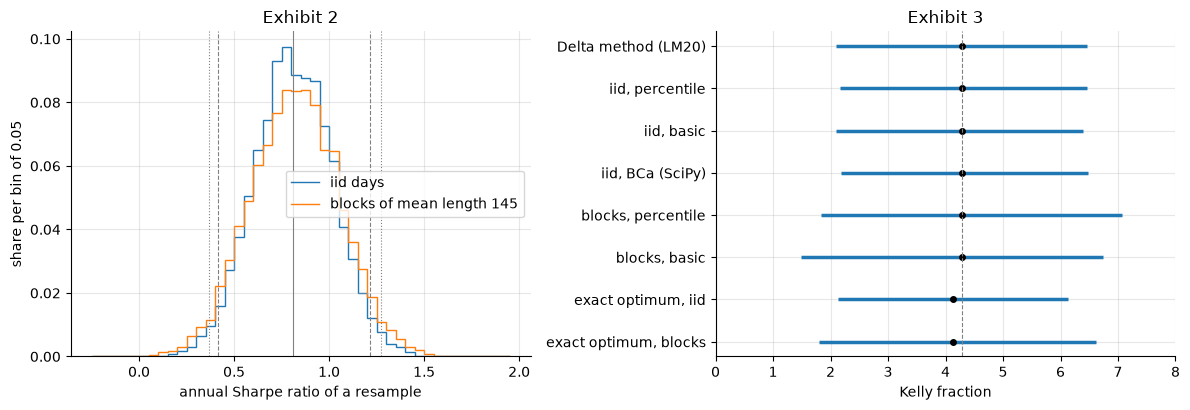

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
edges = np.round(-0.25 + 0.05 * np.arange(45), 6)
for v, lab in ((IID["SR"], "iid days"), (SB["SR"], "blocks of mean length 145")):
    ax1.stairs(np.histogram(v, edges)[0] / B, edges, label=lab)
for x_, ls in ((sr_i.lo, "--"), (sr_i.hi, "--"), (sr_b.lo, ":"), (sr_b.hi, ":"), (OBS["SR"], "-")):
    ax1.axvline(x_, color="gray", ls=ls, lw=0.8)
ax1.set_xlabel("annual Sharpe ratio of a resample"); ax1.set_ylabel("share per bin of 0.05")
ax1.set_title("Exhibit 2"); ax1.legend()
rows3 = [("Delta method (LM20)", KEL, KEL - z * se_k, KEL + z * se_k), ("iid, percentile", KEL, k_i.lo, k_i.hi),
         ("iid, basic", KEL, k_i.blo, k_i.bhi), ("iid, BCa (SciPy)", KEL, *ci["BCa", "Kelly"]),
         ("blocks, percentile", KEL, k_b.lo, k_b.hi), ("blocks, basic", KEL, k_b.blo, k_b.bhi),
         ("exact optimum, iid", OBS["fx"], fx_i.lo, fx_i.hi), ("exact optimum, blocks", OBS["fx"], fx_b.lo, fx_b.hi)]
for j, (lab, est, lo, hi) in enumerate(rows3):
    y = len(rows3) - j
    ax2.hlines(y, lo, hi, lw=2.5); ax2.plot(est, y, "ko", ms=4)
ax2.axvline(KEL, color="gray", ls="--", lw=0.8)
ax2.set_yticks(range(len(rows3), 0, -1), [r_[0] for r_ in rows3]); ax2.set_xlim(0, 8)
ax2.set_xlabel("Kelly fraction"); ax2.set_title("Exhibit 3")
plt.tight_layout(); plt.show()

## Part 4 — What resampling days cannot see

**Example 4 and Exhibit 4.** The lag-1 autocorrelation of $\lvert r_t\rvert$ (LM19's convention: each resample's own mean, divisor $T$) and $\operatorname{VR}(20)$, (19.8), recomputed from each resample's own $\bar r$ and $s_r$, on experiments 2 and 3.

Example 4 rho_1(|r|) (LM19's): 0.161   [book: 0.161]
   LM17's pair correlation: 0.161   [book: 0.161]
   iid mean: -0.0001   [book: -0.0001]
   iid percentile: -0.025   [book: -0.025]
   ...: 0.026   [book: 0.026]
   iid resamples at or above 0.161 in absolute value: 0
   iid SE, the null law's (Section 8): 0.013   [book: 0.013]
   0.161 in these standard errors: 12   [book: 12]
   blocks mean: 0.156   [book: 0.156]
   blocks percentile: 0.10   [book: 0.10]
   ...: 0.21   [book: 0.21]
   Problem 4: iid basic interval: 0.295   [book: 0.295]
   ...: 0.346   [book: 0.346]
VR(20) (LM19's): 1.036   [book: 1.036]
   iid mean: 0.997   [book: 0.997]
   iid percentile: 0.88   [book: 0.88]
   ...: 1.13   [book: 1.13]
   blocks mean: 1.037   [book: 1.037]
   blocks percentile: 0.92   [book: 0.92]
   ...: 1.16   [book: 1.16]
   SEs: iid: 0.065   [book: 0.065]
   blocks: 0.061   [book: 0.061]
   LM19's iid factor (1 - 20/T)/(1 - 1/T): 0.997   [book: 0.997]


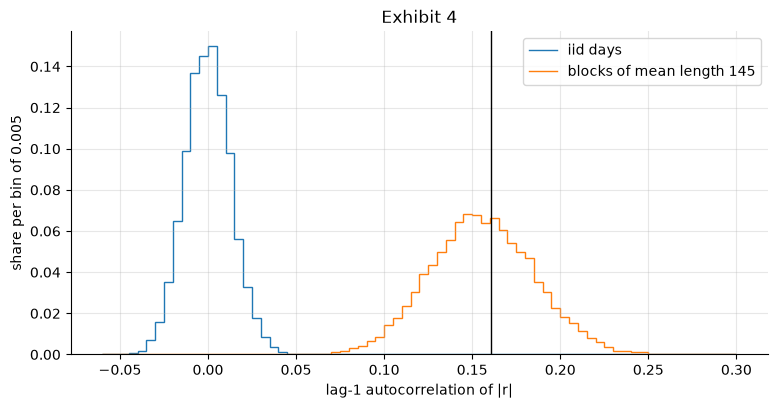

In [11]:
acf_i, acf_b = S["acf"]
vr_i, vr_b = S["VR20"]
show("Example 4 rho_1(|r|) (LM19's)", OBS["acf"], ".3f", "0.161")
show("   LM17's pair correlation", np.corrcoef(np.abs(r[:-1]), np.abs(r[1:]))[0, 1], ".3f", "0.161")
show("   iid mean", acf_i.mean, ".4f", "-0.0001")
show("   iid percentile", acf_i.lo, ".3f", "-0.025"); show("   ...", acf_i.hi, ".3f", "0.026")
print("   iid resamples at or above 0.161 in absolute value:", int((np.abs(IID["acf"]) >= OBS["acf"]).sum()))
show("   iid SE, the null law's (Section 8)", acf_i.se, ".3f", "0.013")
show("   0.161 in these standard errors", OBS["acf"] / acf_i.se, ".0f", "12")
show("   blocks mean", acf_b.mean, ".3f", "0.156")
show("   blocks percentile", acf_b.lo, ".2f", "0.10"); show("   ...", acf_b.hi, ".2f", "0.21")
show("   Problem 4: iid basic interval", acf_i.blo, ".3f", "0.295"); show("   ...", acf_i.bhi, ".3f", "0.346")
show("VR(20) (LM19's)", OBS["VR20"], ".3f", "1.036")
show("   iid mean", vr_i.mean, ".3f", "0.997")
show("   iid percentile", vr_i.lo, ".2f", "0.88"); show("   ...", vr_i.hi, ".2f", "1.13")
show("   blocks mean", vr_b.mean, ".3f", "1.037")
show("   blocks percentile", vr_b.lo, ".2f", "0.92"); show("   ...", vr_b.hi, ".2f", "1.16")
show("   SEs: iid", vr_i.se, ".3f", "0.065"); show("   blocks", vr_b.se, ".3f", "0.061")
show("   LM19's iid factor (1 - 20/T)/(1 - 1/T)", (1 - 20 / T) / (1 - 1 / T), ".3f", "0.997")
fig, ax = plt.subplots()
edges = np.round(-0.06 + 0.005 * np.arange(73), 6)
for v, lab in ((IID["acf"], "iid days"), (SB["acf"], "blocks of mean length 145")):
    ax.stairs(np.histogram(v, edges)[0] / B, edges, label=lab)
ax.axvline(OBS["acf"], color="k", lw=1)
ax.set_xlabel("lag-1 autocorrelation of |r|"); ax.set_ylabel("share per bin of 0.005")
ax.set_title("Exhibit 4"); ax.legend(); plt.show()

## Part 5 — Block bootstraps

The moving and circular block functions draw $\lceil T/\ell\rceil$ starts and cut the joined blocks to $T$ days; the circular one wraps around. arch's `StationaryBootstrap`, `CircularBlockBootstrap` and `MovingBlockBootstrap` draw the same indices from the same generator when it is passed as `seed` (experiment 20: two twin generators from one seed). Then Example 5, Exhibit 5 (experiment 7) and Exhibit 6 (experiments 5 and 6).

In [12]:
def circular_idx(g, T, ell):
    nb = -(-T // ell)                                   # ceil(T / ell) blocks
    st = g.integers(T, size=nb)
    return ((st[:, None] + np.arange(ell)).ravel() % T)[:T]


def moving_idx(g, T, ell):
    nb = -(-T // ell)
    st = g.integers(T - ell + 1, size=nb)               # one of the T - ell + 1 stretches; no wrap
    return (st[:, None] + np.arange(ell)).ravel()[:T]


for cls, fn in ((StationaryBootstrap, stationary_idx), (CircularBlockBootstrap, circular_idx),
                (MovingBlockBootstrap, moving_idx)):
    g1, g2 = rng(20), rng(20)                           # experiment 20: twins
    bs = cls(145, R, seed=g1)
    same = [bool(np.array_equal(bs.index, fn(g2, T, 145))) for _ in bs.bootstrap(3)]
    print(f"{cls.__name__}: the same indices as the NumPy function in three resamples: {same}")
    assert all(same)

StationaryBootstrap: the same indices as the NumPy function in three resamples: [True, True, True]
CircularBlockBootstrap: the same indices as the NumPy function in three resamples: [True, True, True]
MovingBlockBootstrap: the same indices as the NumPy function in three resamples: [True, True, True]


In [13]:
v_i, v_b = S["vol"]
se_s = s * math.sqrt((kurt - 1) / (4 * T)) * SQA
show("Example 5 LM20's SE(s), points a year", 100 * se_s, ".2f", "0.33")
show("   iid bootstrap SE", 100 * v_i.se, ".2f", "0.33")
show("   stationary blocks SE", 100 * v_b.se, ".2f", "1.30")
show("   ratio", v_b.se / v_i.se, ".1f", "3.9")
print(f"   relative SEs: iid {100 * v_i.se / VOL:.2f}%, blocks {100 * v_b.se / VOL:.2f}%")
MB = boot(R, chunks(rng(5), T, moving_idx, 145), exact=False)       # experiment 5
CB = boot(R, chunks(rng(6), T, circular_idx, 145), exact=False)     # experiment 6
rows7 = []
for name, d_ in (("iid days", IID), ("Moving blocks", MB), ("Circular blocks", CB), ("Stationary bootstrap", SB)):
    fv, fk, fs = summ(d_["vol"], OBS["vol"]), summ(d_["Kelly"], KEL), summ(d_["SR"], OBS["SR"])
    rows7.append({"scheme": name, "vol SE (points)": round(100 * fv.se, 2), "vol low %": round(100 * fv.lo, 1),
                  "vol high %": round(100 * fv.hi, 1), "Kelly SE": round(fk.se, 2), "Kelly low": round(fk.lo, 1),
                  "Kelly high": round(fk.hi, 1), "Sharpe SE": round(fs.se, 3)})
x7 = pl.DataFrame(rows7)
print(x7)                                                           # Exhibit 6
assert x7.rows() == [("iid days", 0.33, 18.3, 19.6, 1.1, 2.2, 6.5, 0.205),
                     ("Moving blocks", 1.12, 16.5, 21.0, 1.45, 1.6, 7.2, 0.247),
                     ("Circular blocks", 1.12, 16.7, 21.1, 1.41, 1.7, 7.1, 0.244),
                     ("Stationary bootstrap", 1.3, 16.5, 21.5, 1.34, 1.8, 7.1, 0.233)]
print("knowledge check, Section 5: blocks", math.ceil(T / 145), "| days", math.ceil(T / 145) * 145,
      "| cut", math.ceil(T / 145) * 145 - T)

Example 5 LM20's SE(s), points a year: 0.33   [book: 0.33]
   iid bootstrap SE: 0.33   [book: 0.33]
   stationary blocks SE: 1.30   [book: 1.30]
   ratio: 3.9   [book: 3.9]
   relative SEs: iid 1.75%, blocks 6.84%
shape: (4, 8)
┌────────────┬────────────┬───────────┬────────────┬──────────┬───────────┬────────────┬───────────┐
│ scheme     ┆ vol SE     ┆ vol low % ┆ vol high % ┆ Kelly SE ┆ Kelly low ┆ Kelly high ┆ Sharpe SE │
│ ---        ┆ (points)   ┆ ---       ┆ ---        ┆ ---      ┆ ---       ┆ ---        ┆ ---       │
│ str        ┆ ---        ┆ f64       ┆ f64        ┆ f64      ┆ f64       ┆ f64        ┆ f64       │
│            ┆ f64        ┆           ┆            ┆          ┆           ┆            ┆           │
╞════════════╪════════════╪═══════════╪════════════╪══════════╪═══════════╪════════════╪═══════════╡
│ iid days   ┆ 0.33       ┆ 18.3      ┆ 19.6       ┆ 1.1      ┆ 2.2       ┆ 6.5        ┆ 0.205     │
│ Moving     ┆ 1.12       ┆ 16.5      ┆ 21.0       ┆ 1.45     ┆ 1

Exhibit 5 TR23: largest, %: 44.3   [book: 44.3]
   smallest, %: 7.2   [book: 7.2]
Exhibit 5 iid: largest, %: 27.9   [book: 27.9]
   smallest, %: 11.6   [book: 11.6]
Exhibit 5 blocks: largest, %: 44.3   [book: 44.3]
   smallest, %: 7.2   [book: 7.2]
TR23's extreme windows end on 2008-12-02 and 2014-07-29


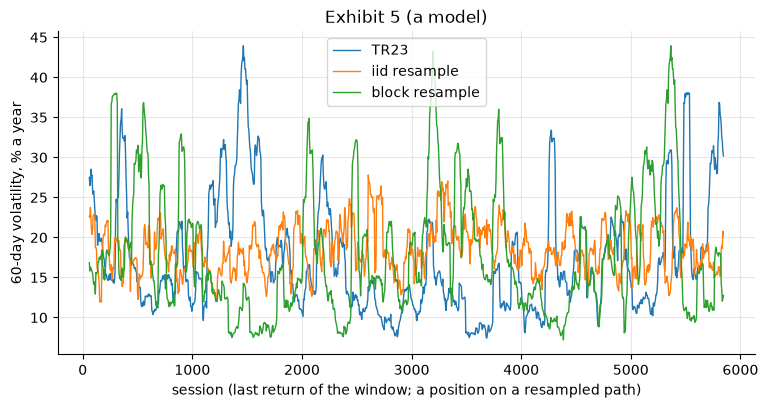

In [14]:
def roll_vol(x, w=60):
    # the standard deviation of each window of w returns (its own mean, divisor w), annualized
    c1, c2 = np.r_[0.0, np.cumsum(x)], np.r_[0.0, np.cumsum(x * x)]
    m1, m2 = (c1[w:] - c1[:-w]) / w, (c2[w:] - c2[:-w]) / w
    return np.sqrt(np.maximum(m2 - m1 * m1, 0.0)) * SQA


g7 = rng(7)                                                         # experiment 7
p_iid = g7.integers(0, T, size=T)
p_blk = stationary_idx(g7, T, 145)
paths = {"TR23": roll_vol(R), "iid resample": roll_vol(R[p_iid]), "block resample": roll_vol(R[p_blk])}
for name, v, hi, lo in (("TR23", paths["TR23"], "44.3", "7.2"), ("iid", paths["iid resample"], "27.9", "11.6"),
                        ("blocks", paths["block resample"], "44.3", "7.2")):
    show(f"Exhibit 5 {name}: largest, %", 100 * v.max(), ".1f", hi)
    show("   smallest, %", 100 * v.min(), ".1f", lo)
print("TR23's extreme windows end on", dates[int(paths["TR23"].argmax()) + 59], "and",
      dates[int(paths["TR23"].argmin()) + 59])
fig, ax = plt.subplots()
sess = np.arange(60, T + 1)
for name, v in paths.items():                                       # every fifth session, as the exhibit
    ax.plot(sess[::5], 100 * v[::5], lw=1, label=name)
ax.set_xlabel("session (last return of the window; a position on a resampled path)")
ax.set_ylabel("60-day volatility, % a year"); ax.set_title("Exhibit 5 (a model)"); ax.legend(); plt.show()

## Part 6 — Choosing the block length

**Example 6.** arch's `optimal_block_length` on $R$, on $(R-\bar R)^2$ and on $(r-\bar r)^2$. The book's rule takes the largest stationary estimate among the squared demeaned simple-return series a statistic involves, rounded: 145 for every TR23 statistic. Then Exhibit 7: experiment 4 draws $B=2{,}000$ stationary resamples at each other length, in increasing order, from one generator.

Example 6 on R: stationary: 3.07   [book: 3.07]
   circular: 3.51   [book: 3.51]
on (R - Rbar)^2: stationary: 144.59   [book: 144.59]
   circular: 165.52   [book: 165.52]
on (r - rbar)^2: stationary: 144.02   [book: 144.02]
arch's cap ceil(min(3 sqrt T, T/3)): 230   [book: 230]
the book's rule: 145   [book: 145]
shape: (11, 5)
┌─────┬──────────┬──────────┬──────────┬──────────┐
│ ell ┆ SR       ┆ Kelly    ┆ vol      ┆ VR20     │
│ --- ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ i64 ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞═════╪══════════╪══════════╪══════════╪══════════╡
│ 1   ┆ 1.0      ┆ 1.0      ┆ 1.0      ┆ 1.0      │
│ 2   ┆ 1.034172 ┆ 1.04539  ┆ 1.175718 ┆ 1.105529 │
│ 3   ┆ 1.050151 ┆ 1.067507 ┆ 1.352341 ┆ 1.166004 │
│ 5   ┆ 1.035898 ┆ 1.057481 ┆ 1.519766 ┆ 1.142979 │
│ 10  ┆ 1.051597 ┆ 1.098377 ┆ 1.842138 ┆ 1.165484 │
│ 20  ┆ 1.082893 ┆ 1.14299  ┆ 2.220433 ┆ 1.102285 │
│ 50  ┆ 1.151132 ┆ 1.235637 ┆ 2.964205 ┆ 1.021026 │
│ 100 ┆ 1.144749 ┆ 1.23509  ┆ 3.568103 ┆ 0.9785

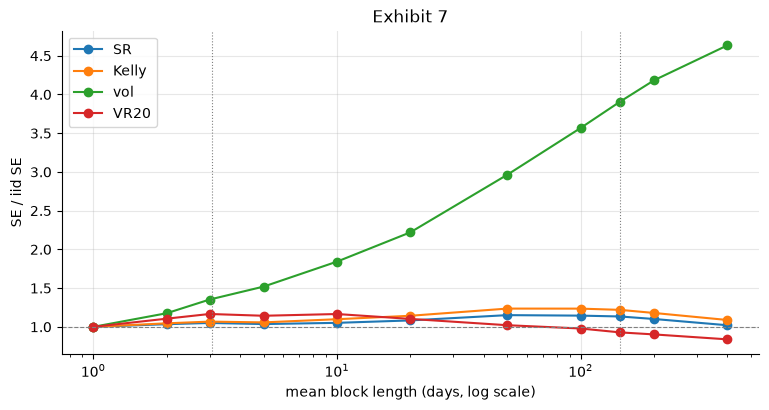

In [15]:
pwR, pwR2, pwr2 = pw(R), pw((R - Rbar) ** 2), pw((r - rbar) ** 2)
show("Example 6 on R: stationary", pwR[0], ".2f", "3.07"); show("   circular", pwR[1], ".2f", "3.51")
show("on (R - Rbar)^2: stationary", pwR2[0], ".2f", "144.59"); show("   circular", pwR2[1], ".2f", "165.52")
show("on (r - rbar)^2: stationary", pwr2[0], ".2f", "144.02")
show("arch's cap ceil(min(3 sqrt T, T/3))", math.ceil(min(3 * math.sqrt(T), T / 3)), "d", "230")
ELL = round(pwR2[0])
show("the book's rule", ELL, "d", "145")
GRID = (2, 3, 5, 10, 20, 50, 100, 200, 400)
g4 = rng(4)                                                         # experiment 4
G4 = {ell: boot(R, chunks(g4, T, stationary_idx, ell, 2000), exact=False) for ell in GRID}
grid = {1: IID, 145: SB, **G4}
KEYS = ("SR", "Kelly", "vol", "VR20")
x6 = pl.DataFrame([{"ell": e, **{k: grid[e][k].std() / IID[k].std() for k in KEYS}} for e in sorted(grid)])
print(x6)                                                           # Exhibit 7
ratio = {e: {k: grid[e][k].std() / IID[k].std() for k in KEYS} for e in grid}
show("volatility at 2", ratio[2]["vol"], ".2f", "1.18")
show("   at 145", ratio[145]["vol"], ".2f", "3.91")
show("   at 400", ratio[400]["vol"], ".2f", "4.63")
show("Sharpe ratio at 3", ratio[3]["SR"], ".2f", "1.05"); show("   at 145", ratio[145]["SR"], ".2f", "1.13")
show("   peak", max(v["SR"] for v in ratio.values()), ".2f", "1.15")
show("   at the length", max(ratio, key=lambda e: ratio[e]["SR"]), "d", "50")
show("Kelly fraction, peak", max(v["Kelly"] for v in ratio.values()), ".2f", "1.24")
show("   at the length", max(ratio, key=lambda e: ratio[e]["Kelly"]), "d", "50")
show("VR(20) at 145", ratio[145]["VR20"], ".2f", "0.93")
show("Sharpe SE from 3 to 145, % change", 100 * (ratio[145]["SR"] / ratio[3]["SR"] - 1), ".0f", "8")
show("Kelly SE from 3 to 145, % change", 100 * (ratio[145]["Kelly"] / ratio[3]["Kelly"] - 1), ".0f", "14")
fig, ax = plt.subplots()
for k in KEYS:
    ax.plot(x6["ell"], x6[k], marker="o", label=k)
ax.set_xscale("log"); ax.axhline(1, color="gray", ls="--", lw=0.8)
for x_ in (pwR[0], pwR2[0]):
    ax.axvline(x_, color="gray", ls=":", lw=0.8)
ax.set_xlabel("mean block length (days, log scale)"); ax.set_ylabel("SE / iid SE")
ax.set_title("Exhibit 7"); ax.legend(); plt.show()

## Part 7 — Intervals the earlier modules left open

**Example 7.** LM16's pair on the days Semiconductor moves at least two standard deviations either way, $\lvert R_t-\bar R\rvert\ge2s$ with the guard, against (16.10) at the full-sample correlation. Each resample re-standardizes, reselects its days and recomputes both correlations (experiment 8 iid, 9 stationary with the pair's own length). These are U28 numbers: on the free plan they differ slightly.

In [16]:
V2 = 1 + 2 * stats.norm.pdf(2.0) / stats.norm.sf(2.0)               # Var(Z | |Z| >= 2), LM16


def corr0(a, b):
    ac, bc = a - a.mean(), b - b.mean()
    return float((ac * bc).mean() / math.sqrt((ac * ac).mean() * (bc * bc).mean()))


def crash(P):
    a, b = P[:, 0], P[:, 1]
    sel = np.abs((a - a.mean()) / a.std()) >= 2 - EPS
    rho = corr0(a, b)
    return corr0(a[sel], b[sel]), rho / math.sqrt(rho**2 + (1 - rho**2) / V2), int(sel.sum())


def one(g, n, ell):
    # one resample's day indices: iid when ell is 1, else stationary
    return g.integers(0, n, size=n) if ell == 1 else stationary_idx(g, n, ell)


c0, m0, n0 = crash(PAIR)
ELL_P = round(max(pw((PAIR[:, j] - PAIR[:, j].mean()) ** 2)[0] for j in (0, 1)))
show("Example 7 big-move days", n0, "d", "223", u28=True)
show("   data correlation", c0, ".4f", "0.7884", u28=True)
show("   (16.10) at rho = 0.5749", m0, ".4f", "0.8598", u28=True)
show("   gap", c0 - m0, ".4f", "-0.0714", u28=True)
show("   the pair's block length", ELL_P, "d", "130", u28=True)
cr = {}
for e, ell in ((8, 1), (9, ELL_P)):                                  # experiments 8 and 9
    g = rng(e)
    cr[e] = np.array([crash(PAIR[one(g, TU, ell)]) for _ in range(B)])
gap8 = summ(cr[8][:, 0] - cr[8][:, 1], c0 - m0)
cor9, gap9 = summ(cr[9][:, 0], c0), summ(cr[9][:, 0] - cr[9][:, 1], c0 - m0)
show("   blocks: correlation SE", cor9.se, ".3f", "0.022", u28=True)
show("   correlation interval", cor9.lo, ".2f", "0.75", u28=True); show("   ...", cor9.hi, ".2f", "0.84", u28=True)
show("   gap SE", gap9.se, ".3f", "0.016", u28=True)
show("   gap interval", gap9.lo, ".3f", "-0.094", u28=True); show("   ...", gap9.hi, ".3f", "-0.033", u28=True)
show("   iid gap interval", gap8.lo, ".3f", "-0.102", u28=True); show("   ...", gap8.hi, ".3f", "-0.037", u28=True)
print("   resampled gaps at or above 0:", int((cr[9][:, 0] - cr[9][:, 1] >= 0).sum()),
      "| big-move days in the block resamples:", int(cr[9][:, 2].min()), "to", int(cr[9][:, 2].max()))

Example 7 big-move days: 223   [book: 223]
   data correlation: 0.7884   [book: 0.7884]
   (16.10) at rho = 0.5749: 0.8598   [book: 0.8598]
   gap: -0.0714   [book: -0.0714]
   the pair's block length: 130   [book: 130]
   blocks: correlation SE: 0.022   [book: 0.022]
   correlation interval: 0.75   [book: 0.75]
   ...: 0.84   [book: 0.84]
   gap SE: 0.016   [book: 0.016]
   gap interval: -0.094   [book: -0.094]
   ...: -0.033   [book: -0.033]
   iid gap interval: -0.102   [book: -0.102]
   ...: -0.037   [book: -0.037]
   resampled gaps at or above 0: 0 | big-move days in the block resamples: 182 to 255


**Example 8.** LM11's first component's share $\lambda_1/N$ of the 28 sectors' correlation matrix, in 2017 and in 2020, with each year's own block length (the largest Politis–White estimate over the 28 squared demeaned series): experiments 10 and 12 iid, 11 and 13 stationary.

In [17]:
def pc1_share(Xy):
    return float(np.linalg.eigvalsh(np.corrcoef(Xy, rowvar=False))[-1] / Xy.shape[1])


pc, shares = {}, {}
for y, e_iid, e_blk, n_p, sh_p, ell_p in (("2017", 10, 11, "246", "34.5", "7"), ("2020", 12, 13, "245", "66.6", "18")):
    Xy = X[uyear == y]
    est = pc1_share(Xy)
    ell_y = round(max(pw((Xy[:, j] - Xy[:, j].mean()) ** 2)[0] for j in range(Xy.shape[1])))
    out = []
    for e, ell in ((e_iid, 1), (e_blk, ell_y)):
        g = rng(e)
        shares[e] = np.array([pc1_share(Xy[one(g, Xy.shape[0], ell)]) for _ in range(B)])
        out.append(summ(shares[e], est))
    pc[y] = (est, ell_y, *out)
    show(f"Example 8 {y}: returns", Xy.shape[0], "d", n_p, u28=True)
    show("   share, %", 100 * est, ".1f", sh_p, u28=True)
    show("   block length", ell_y, "d", ell_p, u28=True)
e17, _, i17, b17 = pc["2017"]
e20, _, i20, b20 = pc["2020"]
show("2017 blocks: SE, points", 100 * b17.se, ".1f", "2.4", u28=True)
show("   interval, %", 100 * b17.lo, ".1f", "30.1", u28=True); show("   ...", 100 * b17.hi, ".1f", "39.4", u28=True)
show("   iid interval, %", 100 * i17.lo, ".1f", "30.7", u28=True); show("   ...", 100 * i17.hi, ".1f", "38.9", u28=True)
show("2020 blocks: SE, points", 100 * b20.se, ".1f", "7.1", u28=True)
show("   percentile, %", 100 * b20.lo, ".1f", "49.6", u28=True); show("   ...", 100 * b20.hi, ".1f", "75.9", u28=True)
show("   basic, %", 100 * b20.blo, ".1f", "57.3", u28=True); show("   ...", 100 * b20.bhi, ".1f", "83.7", u28=True)
show("   resampled mean below the share, points", 100 * (e20 - b20.mean), ".1f", "1.7", u28=True)
print(f"   its batch SE: {100 * bse(shares[13], np.mean):.2f} points (so the module prints one decimal)")
show("   iid interval, %", 100 * i20.lo, ".1f", "58.6", u28=True); show("   ...", 100 * i20.hi, ".1f", "72.8", u28=True)

Example 8 2017: returns: 246   [book: 246]
   share, %: 34.5   [book: 34.5]
   block length: 7   [book: 7]
Example 8 2020: returns: 245   [book: 245]
   share, %: 66.6   [book: 66.6]
   block length: 18   [book: 18]
2017 blocks: SE, points: 2.4   [book: 2.4]
   interval, %: 30.1   [book: 30.1]
   ...: 39.4   [book: 39.4]
   iid interval, %: 30.7   [book: 30.7]
   ...: 38.9   [book: 38.9]
2020 blocks: SE, points: 7.1   [book: 7.1]
   percentile, %: 49.6   [book: 49.6]
   ...: 75.9   [book: 75.9]
   basic, %: 57.3   [book: 57.3]
   ...: 83.7   [book: 83.7]
   resampled mean below the share, points: 1.7   [book: 1.7]
   its batch SE: 0.08 points (so the module prints one decimal)
   iid interval, %: 58.6   [book: 58.6]
   ...: 72.8   [book: 72.8]


**Example 9.** LM18's windows: the $T-m+1$ overlapping sums of $m=\operatorname{round}(5A)=1{,}231$ log returns, the share with a negative sum (recounted exactly with `Fraction` on the closes) and the standard deviation of the sums, on experiments 14 (stationary, $\ell=145$) and 15 (iid).

In [18]:
M5 = round(5 * A)
P = [Fraction(str(x)) for x in raw["price"].to_list()]
under = sum(P[i + M5] < P[i] for i in range(len(P) - M5))


def windows(x):
    c = np.r_[0.0, np.cumsum(x)]
    lg = c[M5:] - c[:-M5]
    return float((lg < 0).mean()), float(lg.std())


sh0, sd0 = windows(r)
show("Example 9 m", M5, ",", "1,231")
show("   windows", T - M5 + 1, ",", "4,619")
show("   under water (Fraction)", under, "d", "191")
show("   share, %", 100 * sh0, ".2f", "4.14")
show("   SD of ln G", sd0, ".3f", "0.283")
show("   sqrt(m) s_r", math.sqrt(M5) * s_r, ".3f", "0.425")
W = {}
for e, ell in ((14, 145), (15, 1)):                                  # experiments 14 and 15
    g = rng(e)
    W[e] = np.array([windows(r[one(g, T, ell)]) for _ in range(B)])
ws14, wd14 = summ(W[14][:, 0], sh0), summ(W[14][:, 1], sd0)
ws15, wd15 = summ(W[15][:, 0], sh0), summ(W[15][:, 1], sd0)
show("blocks: share SE, points", 100 * ws14.se, ".1f", "9.9")
show("   percentile, %", 100 * ws14.lo, ".0f", "0"); show("   ...", 100 * ws14.hi, ".0f", "33")
show("   basic, %", 100 * ws14.blo, ".0f", "-25"); show("   ...", 100 * ws14.bhi, ".0f", "8")
print(f"   batch SEs of the ends: {100 * ws14.lo_b:.2f} and {100 * ws14.hi_b:.2f} points (so whole percents)")
show("   resamples with no window under water", int((W[14][:, 0] == 0).sum()), ",", "3,248")
show("   SD of ln G: SE", wd14.se, ".3f", "0.124")
show("   percentile", wd14.lo, ".2f", "0.20"); show("   ...", wd14.hi, ".2f", "0.68")
show("   resampled mean", wd14.mean, ".3f", "0.386")
show("iid: share SE, points", 100 * ws15.se, ".1f", "8.4")
show("   SD of ln G percentile", wd15.lo, ".2f", "0.19"); show("   ...", wd15.hi, ".2f", "0.58")
show("   SD of ln G resampled mean", wd15.mean, ".3f", "0.357")
print(f"   1 - m/T = {1 - M5 / T:.3f}: overlapping windows understate the variance even for independent days")

Example 9 m: 1,231   [book: 1,231]
   windows: 4,619   [book: 4,619]
   under water (Fraction): 191   [book: 191]
   share, %: 4.14   [book: 4.14]
   SD of ln G: 0.283   [book: 0.283]
   sqrt(m) s_r: 0.425   [book: 0.425]
blocks: share SE, points: 9.9   [book: 9.9]
   percentile, %: 0   [book: 0]
   ...: 33   [book: 33]
   basic, %: -25   [book: -25]
   ...: 8   [book: 8]
   batch SEs of the ends: 0.00 and 0.57 points (so whole percents)
   resamples with no window under water: 3,248   [book: 3,248]
   SD of ln G: SE: 0.124   [book: 0.124]
   percentile: 0.20   [book: 0.20]
   ...: 0.68   [book: 0.68]
   resampled mean: 0.386   [book: 0.386]
iid: share SE, points: 8.4   [book: 8.4]
   SD of ln G percentile: 0.19   [book: 0.19]
   ...: 0.58   [book: 0.58]
   SD of ln G resampled mean: 0.357   [book: 0.357]
   1 - m/T = 0.790: overlapping windows understate the variance even for independent days


In [19]:
x8 = pl.DataFrame([
    {"estimate": "correlation on big-move days (U28 pair)", "value": c0, "ell": ELL_P, "SE": cor9.se, "low": cor9.lo,
     "high": cor9.hi},
    {"estimate": "its gap to (16.10)", "value": c0 - m0, "ell": ELL_P, "SE": gap9.se, "low": gap9.lo, "high": gap9.hi},
    {"estimate": "first component's share, 2017", "value": e17, "ell": pc["2017"][1], "SE": b17.se, "low": b17.lo,
     "high": b17.hi},
    {"estimate": "first component's share, 2020", "value": e20, "ell": pc["2020"][1], "SE": b20.se, "low": b20.lo,
     "high": b20.hi},
    {"estimate": "five-year windows under water", "value": sh0, "ell": 145, "SE": ws14.se, "low": ws14.lo,
     "high": ws14.hi},
    {"estimate": "SD of their ln G", "value": sd0, "ell": 145, "SE": wd14.se, "low": wd14.lo, "high": wd14.hi},
    {"estimate": "VR(20) (TR23)", "value": OBS["VR20"], "ell": 145, "SE": vr_b.se, "low": vr_b.lo, "high": vr_b.hi},
])
x8                                                                  # Exhibit 8

estimate,value,ell,SE,low,high
str,f64,i64,f64,f64,f64
"""correlation on big-move days (…",0.788446,130,0.021688,0.75271,0.838384
"""its gap to (16.10)""",-0.071396,130,0.01554,-0.093704,-0.03272
"""first component's share, 2017""",0.345248,7,0.023625,0.301267,0.394041
"""first component's share, 2020""",0.666199,18,0.071125,0.495546,0.759243
"""five-year windows under water""",0.041351,145,0.099255,0.0,0.330158
"""SD of their ln G""",0.283113,145,0.1238,0.196043,0.67511
"""VR(20) (TR23)""",1.035904,145,0.060772,0.918504,1.15698


## Part 8 — Bootstrap tests

**Example 10.** The t-stat (21.1) with $s_{\mathrm u}$, and the bootstrap p-value (22.4): resample the centred returns $R_t-\bar R$, so that the null $\mu=0$ holds, and count the resampled $\lvert\text{t-stat}\rvert$ at or beyond the observed one. Experiments 16 (7% regime, iid), 17 (7% regime, stationary with the regime's own length) and 18 (full sample, stationary, $\ell=145$); then the knowledge check of Section 8 (experiment 19, uncentred).

In [20]:
def tstat(x):
    return x.mean(axis=-1) / (x.std(axis=-1, ddof=1) / np.sqrt(x.shape[-1]))


tests = {}
for e, x, ell in ((16, R[pre], 1), (17, R[pre], None), (18, R, None)):
    ell = round(pw((x - x.mean()) ** 2)[0]) if ell is None else ell
    x0 = x - x.mean()                                                 # the null imposed
    tb = np.concatenate([tstat(x0[idx]) for idx in chunks(rng(e), x.size, "iid" if ell == 1 else stationary_idx, ell)])
    t0 = float(tstat(x))
    k = int((np.abs(tb) >= abs(t0)).sum())
    tests[e] = (t0, ell, k, k / B, float(tb.std()))
    print(f"experiment {e}: n {x.size}, t-stat {t0:.4f}, ell {ell}: {k} of {B} at or beyond, p {k / B:.4f} "
          f"+- {math.sqrt(k / B * (1 - k / B) / B):.4f}; SD of the resampled t-stats {tb.std():.3f}")
t16, t17, t18 = tests[16], tests[17], tests[18]
show("Example 10 7% regime t-stat (LM21's)", t16[0], ".2f", "2.05")
show("   normal p-value (LM21's)", 2 * stats.norm.sf(abs(t16[0])), ".3f", "0.041")
show("   iid: count", t16[2], "d", "408"); show("   p", t16[3], ".3f", "0.041")
show("   the regime's block length", t17[1], "d", "108")
show("   blocks: count", t17[2], "d", "477"); show("   p", t17[3], ".3f", "0.048")
show("   SDs of the resampled t-stats: iid", t16[4], ".2f", "1.01"); show("   blocks", t17[4], ".2f", "1.03")
show("full sample t-stat", t18[0], ".2f", "3.96")
show("   resampled |t-stat| at or beyond it (blocks of 145)", t18[2], "d", "0")
show("   so (22.4) is 0; the one-sided 95% bound 1 - 0.05^(1/B)", 1 - 0.05 ** (1 / B), ".4f", "0.0003")
tu = np.concatenate([tstat(R[idx]) for idx in chunks(rng(19), T, "iid", 1)])   # experiment 19, not centred
show("knowledge check: mean t-stat of uncentred resamples", tu.mean(), ".2f", "3.96")
print(f"   share at or above the observed t-stat: {(tu >= t18[0]).mean():.4f} (about half)")

experiment 16: n 3077, t-stat 2.0463, ell 1: 408 of 10000 at or beyond, p 0.0408 +- 0.0020; SD of the resampled t-stats 1.006
experiment 17: n 3077, t-stat 2.0463, ell 108: 477 of 10000 at or beyond, p 0.0477 +- 0.0021; SD of the resampled t-stats 1.026
experiment 18: n 5849, t-stat 3.9557, ell 145: 0 of 10000 at or beyond, p 0.0000 +- 0.0000; SD of the resampled t-stats 1.085
Example 10 7% regime t-stat (LM21's): 2.05   [book: 2.05]
   normal p-value (LM21's): 0.041   [book: 0.041]
   iid: count: 408   [book: 408]
   p: 0.041   [book: 0.041]
   the regime's block length: 108   [book: 108]
   blocks: count: 477   [book: 477]
   p: 0.048   [book: 0.048]
   SDs of the resampled t-stats: iid: 1.01   [book: 1.01]
   blocks: 1.03   [book: 1.03]
full sample t-stat: 3.96   [book: 3.96]
   resampled |t-stat| at or beyond it (blocks of 145): 0   [book: 0]
   so (22.4) is 0; the one-sided 95% bound 1 - 0.05^(1/B): 0.0003   [book: 0.0003]
knowledge check: mean t-stat of uncentred resamples: 3.96 

## Part 9 — Problems 6, 10 and 11

**Problem 6.** The stationary bootstrap at $\ell=145$ and $T=5{,}849$: the expected number of blocks, the chance that a block lasts 60 days or more by (22.3), and the predicted mean of $\hat\rho_1(\lvert r\rvert)$ at $\ell=145$ and $\ell=2$, against experiment 3 and experiment 21 ($\ell=2$, $B=2{,}000$). Experiment 26 ($\ell=2$, $B=200{,}000$, about a minute) estimates the expectation at $\ell=2$ itself.

In [21]:
show("(a) expected blocks", 1 + (T - 1) / 145, ".1f", "41.3")
show("(b) Pr(a block lasts 60 days or more)", (1 - 1 / 145) ** 59, ".3f", "0.665")
show("(c) predicted mean at 145", (1 - 1 / 145) * OBS["acf"], ".2f", "0.16")
show("    predicted mean at 2", 0.5 * OBS["acf"], ".2f", "0.08")
e21 = boot(R, chunks(rng(21), T, stationary_idx, 2, 2000), exact=False)["acf"]   # experiment 21
show("    experiment 21: mean", e21.mean(), ".3f", "0.078")
show("    its batch SE", bse(e21, np.mean), ".4f", "0.0005")
show("    experiment 3: mean", acf_b.mean, ".3f", "0.156")
e26 = boot(R, chunks(rng(26), T, stationary_idx, 2, 200_000), exact=False)["acf"]   # experiment 26
show("    experiment 26: mean (the expectation at 2)", e26.mean(), ".4f", "0.0797")
show("    its batch SE", bse(e26, np.mean), ".5f", "0.00005")
show("    experiment 21 below it, in its batch SEs", (e26.mean() - e21.mean()) / bse(e21, np.mean), ".0f", "3")

(a) expected blocks: 41.3   [book: 41.3]
(b) Pr(a block lasts 60 days or more): 0.665   [book: 0.665]
(c) predicted mean at 145: 0.16   [book: 0.16]
    predicted mean at 2: 0.08   [book: 0.08]
    experiment 21: mean: 0.078   [book: 0.078]
    its batch SE: 0.0005   [book: 0.0005]
    experiment 3: mean: 0.156   [book: 0.156]
    experiment 26: mean (the expectation at 2): 0.0797   [book: 0.0797]
    its batch SE: 0.00005   [book: 0.00005]
    experiment 21 below it, in its batch SEs: 3   [book: 3]


**Problem 10.** Section 9's function was checked against arch in Part 5. Here is the solution's code, with $A=246.12$ as Section 9 sets it and the generator named `rng3`, so that the notebook's helper `rng(e)` survives: it re-creates experiment 3's generator and reproduces Exhibit 1's volatility interval.

In [22]:
A = 246.12                                         # as Section 9's code sets it
rng3 = np.random.default_rng([3, 20261011])        # experiment 3
vol = np.empty(10_000)
for c in range(0, 10_000, 500):                    # chunks of 500 rows
    idx = np.stack([stationary_idx(rng3, len(R), 145)
                    for _ in range(500)])
    vol[c:c + 500] = np.sqrt(A) * R[idx].std(axis=1)
q10 = np.quantile(vol, [0.025, 0.975], method="inverted_cdf")
print(q10)
show("Problem 10: low, %", 100 * q10[0], ".1f", "16.5")
show("   high, %", 100 * q10[1], ".1f", "21.5")
A = T / (days / 365.25)                            # back to the sample's unrounded A

[0.16483294 0.21500255]
Problem 10: low, %: 16.5   [book: 16.5]
   high, %: 21.5   [book: 21.5]


**Problem 11 (a stability check).** TR23's 10% regime, 2,772 returns from 1 June 2015: $\hat f$, the book's block length on the regime's squared demeaned returns, and iid (experiment 22) and stationary (experiment 23) percentile intervals for $\hat f$.

In [23]:
R10 = R[~pre]
k10 = R10.mean() / R10.var()
ell10 = round(pw((R10 - R10.mean()) ** 2)[0])


def kelly_boot(e, scheme, ell):
    return np.concatenate([R10[idx].mean(axis=1) / R10[idx].var(axis=1)
                           for idx in chunks(rng(e), R10.size, scheme, ell)])


p22 = summ(kelly_boot(22, "iid", 1), k10)
p23 = summ(kelly_boot(23, stationary_idx, ell10), k10)
show("f_hat, 10% regime", k10, ".2f", "6.06")
show("   the book's block length", ell10, "d", "36")
show("   iid", p22.lo, ".1f", "2.8"); show("   ...", p22.hi, ".1f", "9.6")
show("   blocks", p23.lo, ".1f", "2.6"); show("   ...", p23.hi, ".1f", "10.1")
show("   overlap with the full sample's iid interval", max(p22.lo, k_i.lo), ".1f", "2.8")
show("   ...", min(p22.hi, k_i.hi), ".1f", "6.5")
show("   overlap with the full sample's block interval", max(p23.lo, k_b.lo), ".1f", "2.6")
show("   ...", min(p23.hi, k_b.hi), ".1f", "7.1")

f_hat, 10% regime: 6.06   [book: 6.06]
   the book's block length: 36   [book: 36]
   iid: 2.8   [book: 2.8]
   ...: 9.6   [book: 9.6]
   blocks: 2.6   [book: 2.6]
   ...: 10.1   [book: 10.1]
   overlap with the full sample's iid interval: 2.8   [book: 2.8]
   ...: 6.5   [book: 6.5]
   overlap with the full sample's block interval: 2.6   [book: 2.6]
   ...: 7.1   [book: 7.1]


### Extension: the pair's correlation in the two limit regimes (a stability check)

LM16's lab found that Semiconductor and FinancialInsurance correlated 0.6544 in the 7% regime (1,610 returns to 29 May 2015) and 0.5564 in the 10% regime (2,772 returns from 1 June 2015), and drew no conclusion about chance. Give each regime a stationary block-bootstrap interval, with the book's rule applied to the regime's two squared demeaned series, and give their difference one too, resampling the two regimes independently (experiment 25, one generator: for each of the 10,000 resamples, first the 7% regime, then the 10% regime). The module quotes none of these numbers. Two intervals from one history are a stability check, not a test on later data, and the regime split was chosen after LM16 looked at it.

In [24]:
reg = np.array([d <= "2015-05-29" for d in udates])
parts = {"7%": PAIR[reg], "10%": PAIR[~reg]}
ells = {k: round(max(pw((v[:, j] - v[:, j].mean()) ** 2)[0] for j in (0, 1))) for k, v in parts.items()}
est = {k: corr0(v[:, 0], v[:, 1]) for k, v in parts.items()}
show("7% regime returns", int(reg.sum()), ",", "1,610", u28=True)
show("10% regime returns", int((~reg).sum()), ",", "2,772", u28=True)
show("7% regime correlation (LM16's lab)", est["7%"], ".4f", "0.6544", u28=True)
show("10% regime correlation (LM16's lab)", est["10%"], ".4f", "0.5564", u28=True)
g25 = rng(25)                                                       # experiment 25
vals = np.empty((B, 2))
for i in range(B):
    for j, k in enumerate(("7%", "10%")):
        v = parts[k][stationary_idx(g25, len(parts[k]), ells[k])]
        vals[i, j] = corr0(v[:, 0], v[:, 1])
for j, k in enumerate(("7%", "10%")):
    sm = summ(vals[:, j], est[k])
    print(f"{k} regime: ell {ells[k]}, correlation {est[k]:.4f}, SE {sm.se:.3f}, 95% percentile "
          f"{sm.lo:.3f} to {sm.hi:.3f} (batch SEs of the ends {sm.lo_b:.4f}, {sm.hi_b:.4f})")
dif = summ(vals[:, 0] - vals[:, 1], est["7%"] - est["10%"])
print(f"difference: {dif.est:.4f}, SE {dif.se:.3f}, 95% percentile {dif.lo:.3f} to {dif.hi:.3f}; "
      f"resamples with the 10% regime's correlation at or above the 7% regime's: {int((vals[:, 0] <= vals[:, 1]).sum())}")
# your code: the same for the crash correlation of Example 7 in each regime; why are its intervals so much wider?

7% regime returns: 1,610   [book: 1,610]
10% regime returns: 2,772   [book: 2,772]
7% regime correlation (LM16's lab): 0.6544   [book: 0.6544]
10% regime correlation (LM16's lab): 0.5564   [book: 0.5564]
7% regime: ell 74, correlation 0.6544, SE 0.026, 95% percentile 0.597 to 0.700 (batch SEs of the ends 0.0009, 0.0005)
10% regime: ell 38, correlation 0.5564, SE 0.034, 95% percentile 0.488 to 0.619 (batch SEs of the ends 0.0006, 0.0008)
difference: 0.0981, SE 0.043, 95% percentile 0.013 to 0.181; resamples with the 10% regime's correlation at or above the 7% regime's: 117
